# 03 - Inference
Load the saved pipeline, score patients, and call the API in-process (same code path as the container).

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
%matplotlib inline
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
from heart import config, data
import json
from heart.predict import load_model, load_metadata, predict_records

In [2]:
model = load_model()
meta = load_metadata()
print(meta['model_name'], meta['model_version'])
print('test metrics:', meta['test_metrics'])

logistic_regression 1.0.0-202610181958
test metrics: {'accuracy': 0.8361, 'precision': 0.8462, 'recall': 0.7857, 'f1': 0.8148, 'roc_auc': 0.9177}


## Score two example patients

In [3]:
patients = [
  dict(age=63, sex=1, cp=3, trestbps=145, chol=233, fbs=1, restecg=0, thalach=150, exang=0, oldpeak=2.3, slope=0, ca=0, thal=1),
  dict(age=64, sex=1, cp=0, trestbps=160, chol=300, fbs=0, restecg=1, thalach=105, exang=1, oldpeak=3.5, slope=1, ca=3, thal=3),
  dict(age=35, sex=0, cp=2, trestbps=115, chol=190, fbs=0, restecg=1, thalach=185, exang=0, oldpeak=0.0, slope=2, ca=None, thal=None)]
pd.DataFrame(predict_records(model, patients))

,prediction,label,probability_disease,confidence
0,0,no heart disease,0.3952,0.6048
1,1,heart disease,0.9890,0.9890
2,0,no heart disease,0.0244,0.9756


The third record leaves `ca` and `thal` empty; the pipeline's imputers handle it.

## Call the REST API (in-process with FastAPI's TestClient)

In [4]:
from fastapi.testclient import TestClient
from heart.api import app
with TestClient(app) as client:
    print(client.get('/health').json())
    r = client.post('/predict', json=patients[0]); print(r.status_code, json.dumps(r.json(), indent=2))
    bad = client.post('/predict', json=dict(patients[0], age=-3)); print('invalid input ->', bad.status_code)

{"ts": "2026-10-18T20:02:51+0000", "level": "INFO", "logger": "heart.api", "msg": "model loaded", "model_path": "/home/claude/heart-disease-mlops/models/heart_pipeline.joblib", "model_version": "1.0.0-202610181958"}


{"ts": "2026-10-18T20:02:51+0000", "level": "INFO", "logger": "heart.api", "msg": "request", "request_id": "cb06ff9b3b6e", "method": "GET", "path": "/health", "status": 200, "latency_ms": 1.35, "client": "testclient"}


{"ts": "2026-10-18T20:02:51+0000", "level": "INFO", "logger": "heart.api", "msg": "prediction", "request_id": "0dcee27f880c", "prediction": 0, "confidence": 0.6048, "model_version": "1.0.0-202610181958"}


{"ts": "2026-10-18T20:02:51+0000", "level": "INFO", "logger": "heart.api", "msg": "request", "request_id": "0dcee27f880c", "method": "POST", "path": "/predict", "status": 200, "latency_ms": 13.62, "client": "testclient"}


{"ts": "2026-10-18T20:02:51+0000", "level": "INFO", "logger": "heart.api", "msg": "request", "request_id": "9dd286ad363c", "method": "POST", "path": "/predict", "status": 422, "latency_ms": 0.56, "client": "testclient"}


{'status': 'ok', 'model_version': '1.0.0-202610181958'}
200 {
  "prediction": 0,
  "label": "no heart disease",
  "confidence": 0.6048,
  "probability_disease": 0.3952,
  "model_version": "1.0.0-202610181958"
}
invalid input -> 422


Equivalent `curl` once the server or container is running:
```bash
curl -X POST http://localhost:8000/predict -H 'Content-Type: application/json' \
  -d '{"age":63,"sex":1,"cp":3,"trestbps":145,"chol":233,"fbs":1,"restecg":0,"thalach":150,"exang":0,"oldpeak":2.3,"slope":0,"ca":0,"thal":1}'
```

## Distribution of predicted risk on the whole dataset

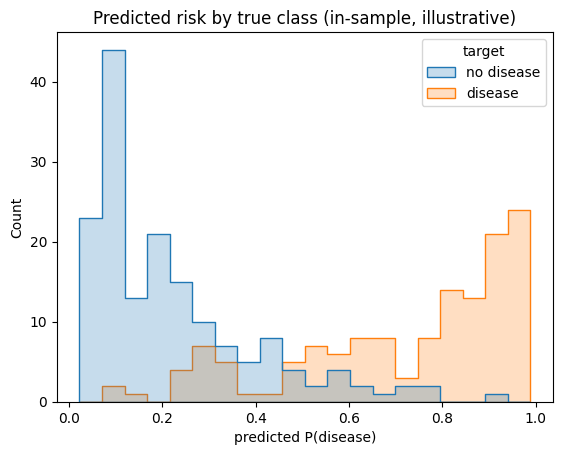

In [5]:
d = data.load_clean(); probs = [r['probability_disease'] for r in predict_records(model, d[config.FEATURES].to_dict('records'))]
sns.histplot(x=probs, hue=d.target.map({0:'no disease',1:'disease'}), bins=20, element='step'); plt.xlabel('predicted P(disease)'); plt.title('Predicted risk by true class (in-sample, illustrative)'); plt.show()